# 02 — Data Preparation

This notebook follows Notebook 01 specification. It is deliberately a data-preparation notebook, not a modelling notebook.

The preparation pipeline will produce three separate representations of the same 1,131 respondents:

|Clustering method|Input prepared here|
|--|--|
|K-Modes|Original categorical responses|
|MCA + K-Means|One-hot indicator matrix; MCA is fitted in the modelling notebook|
|Agglomerative hierarchical clustering + Gower|Typed categorical data and domain-balanced Gower dissimilarity matrix|
|HDBSCAN + Gower|The same domain-balanced Gower dissimilarity matrix|

The primary feature set remains exactly 15 workplace-climate questions across the three domains defined in Notebook 01. Demographics, age, personal diagnosis and treatment history, location, company size, remote work, and other contextual variables will not enter the clustering matrices.

Important missing-value decision: the supplied 1,131-person cohort has no missing values in the 15 selected clustering features. Therefore, this notebook does not impute those features. It checks that this remains true and stops if a different source version introduces missing values.

Gender is cleaned for descriptive profiling only. It is not a clustering feature.

## 1. Setup

### 1.1 Purpose
This notebook transforms the interim dataset produced by Notebook 01 into validated, algorithm-specific modelling inputs.

The work includes:
1. Loading the interim dataset.
2. Reconstructing and validating the eligible respondent cohort.
3. Standardising text formatting without changing the meaning of responses.
4. Harmonising gender for descriptive profiling only.
5. Defining the 15 primary clustering features and their measurement types.
6. Auditing missingness and observed response categories.
7. Preparing the K-Modes categorical matrix.
8. Preparing the MCA indicator matrix.
9. Preparing typed input for Gower dissimilarity.
10. Constructing a domain-balanced Gower dissimilarity matrix.
11. Measuring pairwise categorical association using bias-corrected Cramér’s V.
12. Visualising the prepared data and its important characteristics.
13. Validating and exporting all modelling inputs.

No clustering algorithm or MCA model is fitted in this notebook. Those activities belong in the modelling notebook.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency

# Reproducibility and display

RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
)

# Project paths

ROOT = (
    Path.cwd().resolve().parent
    if Path.cwd().resolve().name == "notebooks"
    else Path.cwd().resolve()
)

INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"

FIGURES_DIR = (
    ROOT / "reports"
    / "figures"
    / "data_preparation"
)

RESULTS_DIR = (
    ROOT / "reports"
    / "results"
    / "data_preparation"
)

INPUT_FILE = (
    INTERIM_DIR
    / "osmi_2016_renamed_interim.csv"
)

for directory in [
    PROCESSED_DIR,
    FIGURES_DIR,
    RESULTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Required Notebook 01 output was not found:\n{INPUT_FILE}\n\n"
        "Run Notebook 01 first, and confirm that it exports "
        "osmi_2016_renamed_interim.csv to data/interim/."
    )

print(f"Project root: {ROOT}")
print(f"Input file:   {INPUT_FILE}")
print(f"Output path:  {PROCESSED_DIR}")
print(f"Figures path: {FIGURES_DIR}")

Project root: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering
Input file:   C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\data\interim\osmi_2016_renamed_interim.csv
Output path:  C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\data\processed
Figures path: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\reports\figures\data_preparation


## 2. Load the Interim Dataset

### 2.1 Loading the Correct Source
Notebook 01 is responsible for renaming the original survey columns. Notebook 02 must use that renamed interim file rather than repeat the original column-renaming process.

This separation is important because it creates a clear division of responsibility:
- Notebook 01 establishes the dataset's meaning, scope and selected variables.
- Notebook 02 prepares the selected data for the clustering algorithms.
- The modelling notebook fits and evaluates the clustering models.
The interim dataset is expected to contain the original respondent records with standardised column names. It is not yet the final clustering matrix.

In [2]:
df = pd.read_csv(INPUT_FILE)

# Preserve the position of every row in the interim source file.
df.insert(
    0,
    "source_row_position",
    np.arange(len(df), dtype=np.int64),
)

print("Loaded interim dataset")
print("-" * 60)
print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Loaded interim dataset
------------------------------------------------------------
Rows:    1,433
Columns: 64


,source_row_position,self_employed,company_size,tech_company,tech_role,mh_benefits,mh_options_awareness,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,mh_vs_ph_seriousness,observed_mh_consequences,medical_coverage_mh,know_external_resources,reveal_mh_clients,client_reveal_neg_impact,reveal_mh_coworkers,coworker_reveal_neg_impact,mh_productivity_affected,mh_productivity_pct,has_previous_employers,prev_mh_benefits,prev_mh_awareness,prev_mh_discussion,prev_mh_resources,prev_mh_anonymity,prev_mh_consequences,prev_ph_consequences,prev_willingness_coworkers,prev_willingness_supervisor,prev_mh_vs_ph_seriousness,prev_observed_mh_consequences,interview_ph_reveal,interview_ph_reveal_why,interview_mh_reveal,interview_mh_reveal_why,mh_hurt_career,coworker_negative_view,share_with_friends_family,observed_bad_mh_handling,observed_bad_handling_impact,family_history_mh,past_mh_disorder,current_mh_disorder,current_diagnosed_conditions,suspected_conditions,diagnosed_by_pro,pro_diagnosed_conditions,sought_mh_treatment,mh_interference_treated,mh_interference_untreated,age,gender,country_live,us_state_live,country_work,us_state_work,work_position,work_remote
0,0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,No,No,Maybe,Yes,I don't know,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"No, none did",N/A (not currently aware),I don't know,None did,I don't know,Some of them,None of them,Some of my previous employers,Some of my previous employers,I don't know,None of them,Maybe,NaN,Maybe,NaN,Maybe,"No, I don't think they would",Somewhat open,No,NaN,No,Yes,No,NaN,NaN,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)",0,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,No,No,Maybe,Yes,Yes,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"Yes, they all did",I was aware of some,None did,Some did,"Yes, always",None of them,None of them,"No, at none of my previous employers",Some of my previous employers,Some did,None of them,Maybe,It would depend on the health issue. If there is a health issue that would not immediately affec...,No,"While mental health has become a more prominent issue recently, I feel like there is still a lot...","No, I don't think it would","No, I don't think they would",Somewhat open,No,NaN,Yes,Yes,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder,...",NaN,Yes,"Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder,...",1,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,Maybe,No,Maybe,Maybe,I don't know,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,"No, none did",N/A (not currently aware),None did,Some did,I don't know,I don't know,Some of them,Some of my previous employers,I don't know,I don't know,Some of them,Yes,"They would provable need to know, to Judge if I can do my job or not.",Yes,"Stigma, mainly.",Maybe,Maybe,Somewhat open,Maybe/Not sure,Yes,No,Maybe,No,NaN,NaN,No,NaN,1,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,"Yes, I know several","Sometimes, if it comes up",I'm not sure,"Sometimes, if it comes up",I'm not sure,Yes,1-25%,1,Some did,N/A (not currently aware),None did,None did,I don't know,Some of them,Some of them,Some of my previous employers,Some of my previous employers,I don't know,Some of them,Yes,"old back injury, doesn't cause me many issues but occasionally impacts my ability to work at desk",Maybe,would not if I was not 100% sure that the disclosure would not affect 

### 2.2 Initial Structural Inspection
The dataset is inspected before cohort filtering to confirm that the expected fields are available and that the source has not unexpectedly changed.

The three cohort-defining fields are:
- self_employed
- tech_company
- tech_role

The 15 selected workplace-climate features and the descriptive gender field must also be present.

In [3]:
required_columns = [
    "self_employed",
    "tech_company",
    "tech_role",
    "gender",
]

missing_required_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_required_columns:
    raise KeyError(
        "The interim dataset is missing required columns: "
        f"{missing_required_columns}"
    )

print("Required cohort and profiling columns are present.")

display(
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_values": df.isna().sum(),
        "missing_percentage": (
            df.isna().mean() * 100
        ).round(2),
        "distinct_values": df.nunique(dropna=True),
    }).sort_values(
        "missing_percentage",
        ascending=False,
    )
)

Required cohort and profiling columns are present.


,dtype,missing_values,missing_percentage,distinct_values
client_reveal_neg_impact,str,1289,89.95,3
mh_productivity_pct,str,1229,85.76,4
tech_role,float64,1170,81.65,2
mh_productivity_affected,str,1146,79.97,4
medical_coverage_mh,float64,1146,79.97,2
reveal_mh_clients,str,1146,79.97,5
reveal_mh_coworkers,str,1146,79.97,5
coworker_reveal_neg_impact,str,1146,79.97,4
know_external_resources,str,1146,79.97,3
suspected_conditions,str,1111,77.53,99


## 3. Reconstruct the Eligible Respondent Cohort

### 3.1 Cohort Definition
The clustering analysis focuses on respondents who:
1. Are not self-employed; and
2. Either work for a technology company or hold a technology-related role.

The cohort rule is:
$$
\text{Eligible}_i =
(\text{SelfEmployed}_i = 0)
\land
\left[
(\text{TechCompany}_i = 1)
\lor
(\text{TechRole}_i = 1)
\right]
$$

The logical OR is intentional. A respondent qualifies if they work for a technology company or have a technology-related role, provided they are not self-employed.

The expected cohort contains 1,131 respondents. A different count indicates that the source file, column definitions or cohort logic must be investigated before proceeding.

In [5]:
# Missing values in the technology fields are treated as not affirmative.
cohort_columns = [
    "self_employed",
    "tech_company",
    "tech_role",
]

cohort_missingness = df[cohort_columns].isna().sum()

print("Missing values in cohort-defining fields:")
display(cohort_missingness[cohort_missingness > 0])

# Reconstruct the cohort using the Notebook 01 definition.
cohort_mask = (
    df["self_employed"].eq(0)
    & (
        df["tech_company"].eq(1)
        | df["tech_role"].eq(1)
    )
)

cohort = df.loc[cohort_mask].copy()

# Preserve the source row position for lineage.
cohort = cohort.reset_index(drop=True)

cohort_audit = pd.DataFrame({
    "criterion": [
        "All interim respondents",
        "Not self-employed",
        "Not self-employed and technology employer",
        "Not self-employed and technology role",
        "Eligible cohort: technology employer OR technology role",
    ],
    "respondents": [
        len(df),
        int(df["self_employed"].eq(0).sum()),
        int(
            (
                df["self_employed"].eq(0)
                & df["tech_company"].eq(1)
            ).sum()
        ),
        int(
            (
                df["self_employed"].eq(0)
                & df["tech_role"].eq(1)
            ).sum()
        ),
        len(cohort),
    ],
})

display(cohort_audit)

EXPECTED_COHORT_SIZE = 1131

if len(cohort) != EXPECTED_COHORT_SIZE:
    raise AssertionError(
        f"Expected {EXPECTED_COHORT_SIZE:,} eligible respondents, "
        f"but found {len(cohort):,}. "
        "Investigate the input file and cohort definition."
    )

print(
    f"Validated eligible cohort: {len(cohort):,} respondents."
)

Missing values in cohort-defining fields:


tech_company     287
tech_role       1170
dtype: int64

,criterion,respondents
0,All interim respondents,1433
1,Not self-employed,1146
2,Not self-employed and technology employer,883
3,Not self-employed and technology role,248
4,Eligible cohort: technology employer OR technology role,1131


Validated eligible cohort: 1,131 respondents.


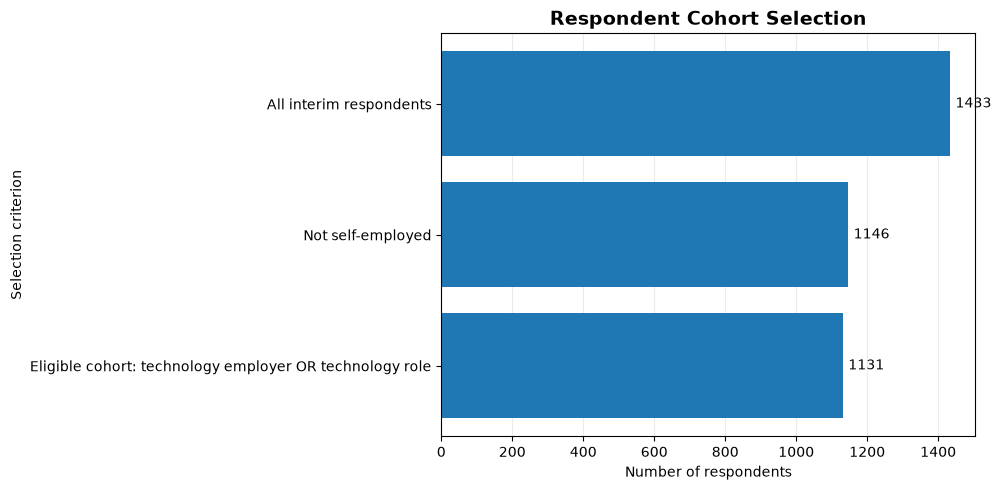

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_data = cohort_audit.iloc[
    [0, 1, 4]
].copy()

bars = ax.barh(
    plot_data["criterion"],
    plot_data["respondents"],
)

ax.set_title(
    "Respondent Cohort Selection",
    fontsize=14,
    weight="bold",
)

ax.set_xlabel("Number of respondents")
ax.set_ylabel("Selection criterion")

ax.bar_label(
    bars,
    fmt="%.0f",
    padding=4,
)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cohort_selection.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 4. Standardise Text Formatting

### 4.1 Text Cleaning Without Changing Response Meaning
Survey data can contain inconsistent formatting, including:
- Leading and trailing whitespace.
- Repeated spaces.
- Non-breaking spaces.
- Tabs and newline characters.
- Empty strings that should be treated as missing values.
These inconsistencies can cause identical responses to be interpreted as separate categories. For example, "Male" and "Male " should not be counted as two different responses.

The cleaning operation standardises formatting only. It does not merge semantically different answers, infer missing responses or convert categories into numerical values.

Missing values remain missing.

In [7]:
def clean_text_value(value):
    """
    Standardise text formatting without changing response meaning.

    - Preserve non-string values.
    - Replace non-breaking spaces.
    - Replace tabs and line breaks with spaces.
    - Collapse repeated whitespace.
    - Remove leading and trailing whitespace.
    - Convert blank strings to pd.NA.
    """
    if not isinstance(value, str):
        return value

    value = value.replace("\u00a0", " ")
    value = re.sub(r"[\t\r\n]+", " ", value)
    value = re.sub(r"\s+", " ", value)
    value = value.strip()

    if value == "":
        return pd.NA

    return value


def clean_dataframe_text(dataframe):
    """
    Apply text formatting standardisation to object/string columns.
    """
    result = dataframe.copy()

    text_columns = result.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        result[column] = (
            result[column]
            .map(clean_text_value)
        )

    return result


# Apply to the full respondent dataset and the eligible cohort.
df_clean = clean_dataframe_text(df)
cohort_clean = clean_dataframe_text(cohort)

print("Text formatting standardisation completed.")

print(
    "Text columns cleaned:",
    len(
        df.select_dtypes(
            include=["object", "string"]
        ).columns
    ),
)

Text formatting standardisation completed.
Text columns cleaned: 56


### 4.2 Verify the Cleaning Operation
The cleaning operation should not alter the number of respondents or columns. It should only standardise text formatting and convert blank strings into missing values.

In [8]:
assert df_clean.shape == df.shape
assert cohort_clean.shape == cohort.shape

assert (
    cohort_clean["source_row_position"].to_numpy()
    == cohort["source_row_position"].to_numpy()
).all()

print("Text-cleaning structural checks passed.")

Text-cleaning structural checks passed.


## 5. Gender Harmonisation for Descriptive Profiling

### 5.1 Why Gender is not a Clustering Feature

Gender is retained for descriptive profiling but excluded from the clustering input.

The objective of this clustering project is to identify patterns in workplace mental-health support, psychological safety and disclosure-related career climate. Including gender in the distance calculations would change the question being answered: respondents could become similar or dissimilar partly because of their gender rather than their workplace experiences.

Gender is therefore not included in:
- The K-Modes matrix.
- The MCA indicator matrix.
- The Gower input.
- The Gower dissimilarity matrix.

The raw survey field contains inconsistent spelling, capitalisation, abbreviations and free-text responses. For descriptive reporting, the values are harmonised into three reporting categories:
- Male
- Female
- Other

Three missing values remain missing. They are not imputed.

The Other category is a pragmatic reporting category for this particular three-category profile. It does not imply that all identities grouped there are identical.

In [9]:
male_values = [
    "male",
    "Male",
    "M",
    "m",
    "man",
    "Cis male",
    "Male.",
    "male 9:1 female, roughly",
    "Male (cis)",
    "Man",
    "Sex is male",
    "cis male",
    "Malr",
    "Dude",
    "mail",
    "M|",
    "Male/genderqueer",
    "male ",
    "Cis Male",
    "cisdude",
    "cis man",
    "MALE",
    "Male ",
    "Male (trans, FtM)",
    "I'm a man why didn't you make this a drop down question. You should of asked sex? And I would of answered yes please. Seriously how much text can this take? "
]

female_values = [
    "Female",
    "female",
    "female ",
    "F",
    "Woman",
    "fm",
    "f",
    "Cis female ",
    "Transitioned, M2F",
    " Female",
    "Cis-woman",
    "AFAB",
    "Genderfluid (born female)",
    "Female ",
    "woman",
    "female/woman",
    "Cisgender Female", "fem",
    "female-bodied; no feelings about gender",
    "Female (props for making this a freeform field, though)",
    "I identify as female.",
    "Female assigned at birth ",
    "Female or Multi-Gender Femme",
    "mtf",
    "Transgender woman"
]

other_values = [
    "non-binary",
    "Agender",
    "Nonbinary",
    "Queer",
    "nb masculine",
    "human",
    "genderqueer woman",
    "genderqueer",
    "Unicorn",
    "Bigender",
    "Enby",
    "Other",
    "Other/Transfeminine",
    "Human",
    "Genderqueer",
    "Genderflux demi-girl",
    "Genderfluid",
    "Fluid",
    "Enby Bigender",
    "Androgynous",
    "none of your business"
]


def gender_key(value):
    """
    Create a normalised key for gender matching.
    """
    if pd.isna(value):
        return None

    cleaned = clean_text_value(value)

    if pd.isna(cleaned):
        return None

    return str(cleaned).casefold()


male_keys = {
    gender_key(value)
    for value in male_values
}

female_keys = {
    gender_key(value)
    for value in female_values
}

other_keys = {
    gender_key(value)
    for value in other_values
}

# Check that the explicit mapping lists do not conflict.
assert male_keys.isdisjoint(female_keys)
assert male_keys.isdisjoint(other_keys)
assert female_keys.isdisjoint(other_keys)


def harmonise_gender(value):
    """
    Harmonise gender for descriptive profiling only.

    Unambiguous male and female responses are mapped to their
    respective categories. Other non-missing free-text responses
    are grouped under Other for the requested three-category
    descriptive profile. Missing values remain missing.
    """
    key = gender_key(value)

    if key is None:
        return pd.NA

    if key in male_keys:
        return "Male"

    if key in female_keys:
        return "Female"

    return "Other"


cohort_clean["gender_profile"] = (
    cohort_clean["gender"]
    .map(harmonise_gender)
    .astype("string")
)

gender_counts = (
    cohort_clean["gender_profile"]
    .value_counts(dropna=False)
    .rename_axis("gender_category")
    .reset_index(name="respondents")
)

display(gender_counts)

,gender_category,respondents
0,Male,843
1,Female,264
2,Other,21
3,<NA>,3


### 5.2 Validate the Harmonised Gender Profile

The gender distribution must be calculated on the eligible cohort, not on the full dataset. The expected cohort total is 1,131, so the expected counts above must sum to 1,433 only if they refer to the full source dataset. This distinction matters.

For the eligible cohort, the notebook must report the actual counts and must not impose full-dataset gender counts as cohort counts.

In [13]:
# Harmonise the full dataset for the full-dataset gender audit.
df_clean["gender_profile"] = (
    df_clean["gender"]
    .map(harmonise_gender)
    .astype("string")
)

# Recreate the eligible cohort from the cleaned full dataset.
cohort_clean = df_clean.loc[
    cohort_mask.to_numpy()
].copy().reset_index(drop=True)

# Full-source gender audit.
full_gender_counts = (
    df_clean["gender_profile"]
    .value_counts(dropna=False)
)

expected_full_gender_counts = {
    "Male": 1060,
    "Female": 345,
    "Other": 25,
}

for category, expected_count in expected_full_gender_counts.items():
    actual_count = int(
        full_gender_counts.get(category, 0)
    )

    if actual_count != expected_count:
        raise AssertionError(
            f"Full-dataset gender count mismatch for {category}: "
            f"expected {expected_count}, found {actual_count}."
        )

actual_missing_gender = int(
    df_clean["gender_profile"].isna().sum()
)

if actual_missing_gender != 3:
    raise AssertionError(
        "Expected 3 missing gender values in the full source dataset, "
        f"found {actual_missing_gender}."
    )

assert int(full_gender_counts.sum()) == 1433

print("Validated full-source gender profile:")
display(
    full_gender_counts
    .rename("respondents")
    .to_frame()
)

# Eligible-cohort gender profile is reported separately.
cohort_gender_counts = (
    cohort_clean["gender_profile"]
    .value_counts(dropna=False)
)

print("Gender profile within the eligible cohort:")
display(
    cohort_gender_counts
    .rename("respondents")
    .to_frame()
)

assert int(cohort_gender_counts.sum()) == len(cohort_clean)

Validated full-source gender profile:


,respondents
gender_profile,
Male,1060
Female,345
Other,25
<NA>,3


Gender profile within the eligible cohort:


,respondents
gender_profile,
Male,843
Female,264
Other,21
<NA>,3


The harmonisation is performed only to support descriptive profiling. The original gender field is preserved in the cleaned respondent dataset, and the harmonised `gender_profile` field is an additional reporting variable.

The three missing gender responses remain missing. There is no statistical or methodological reason to guess the gender of these respondents.

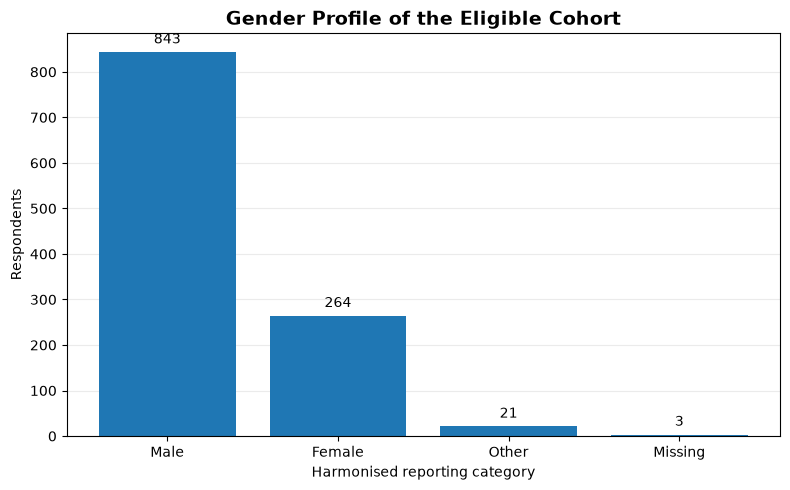

In [14]:
gender_plot = (
    cohort_clean["gender_profile"]
    .fillna("Missing")
    .value_counts()
    .reindex(
        ["Male", "Female", "Other", "Missing"],
        fill_value=0,
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    gender_plot.index,
    gender_plot.values,
)

ax.set_title(
    "Gender Profile of the Eligible Cohort",
    fontsize=14,
    weight="bold",
)

ax.set_xlabel("Harmonised reporting category")
ax.set_ylabel("Respondents")

ax.bar_label(
    bars,
    fmt="%.0f",
    padding=4,
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gender_profile.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 6. Define the Primary Clustering Feature Set

### 6.1 The 15 Selected Features

The clustering analysis uses the 15 workplace-climate features selected in Notebook 01. They represent three related but distinct domains.


| Domain | Number of features | Workplace-climate construct |
| :--- | :---: | :--- |
| Employer support and policy | 6 | Organisational benefits, resources, policies and perceived support |
| Psychological safety and observed stigma | 5 | Perceived consequences of disclosure and comfort discussing mental health |
| Disclosure and career climate | 4 | Perceived career consequences of disclosure and coworker attitudes |
| **Total** | **15** | |


The features are retained individually. Questions within a domain may be conceptually related, but they are not automatically redundant. For example, comfort discussing mental health with a supervisor is not the same construct as comfort discussing it with coworkers.

The domain structure is also used later to calculate a balanced Gower dissimilarity. This prevents the domain with six questions from automatically receiving more total influence than the domain with four questions.

In [15]:
FEATURES_BY_DOMAIN = {
    "employer_support": [
        "mh_benefits",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_vs_ph_seriousness",
    ],

    "psychological_safety": [
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "observed_mh_consequences",
    ],

    "disclosure_career_climate": [
        "interview_ph_reveal",
        "interview_mh_reveal",
        "mh_hurt_career",
        "coworker_negative_view",
    ],
}

PRIMARY_FEATURES = [
    feature
    for features in FEATURES_BY_DOMAIN.values()
    for feature in features
]

assert len(PRIMARY_FEATURES) == 15
assert len(set(PRIMARY_FEATURES)) == 15

missing_features = [
    feature
    for feature in PRIMARY_FEATURES
    if feature not in cohort_clean.columns
]

if missing_features:
    raise KeyError(
        "The interim dataset does not contain all 15 selected features: "
        f"{missing_features}"
    )

print("Primary feature count:", len(PRIMARY_FEATURES))

for domain, features in FEATURES_BY_DOMAIN.items():
    print(f"{domain}: {len(features)} features")

Primary feature count: 15
employer_support: 6 features
psychological_safety: 5 features
disclosure_career_climate: 4 features


### 6.2 Measurement Levels and Algorithm-Specific Treatment

The 15 variables are categorical survey responses. Their measurement levels must be respected when constructing the different clustering representations.

The selected feature `mh_medical_leave_ease` is ordinal for its five substantive responses:
1. Very difficult
2. Somewhat difficult
3. Neither easy nor difficult
4. Somewhat easy
5. Very easy

The response "I don't know" is not a sixth point on this ordered scale. It does not mean that leave is more difficult than Very difficult, nor does it mean that leave is neutral. It is an unordered response indicating that the respondent does not know.

The other 14 features are treated as nominal categorical responses for this project. Even where answers look like Yes, Maybe and No, Notebook 01's selected measurement specification treats them as categories rather than assigning artificial numeric distances.

The resulting treatment is:

|Representation|Treatment of nominal responses|Treatment of leave-ease response|
|:--|:--|:--|
|K-Modes|Original category labels|All six labels treated as categories|
|MCA indicator matrix|One-hot categorical indicators|All six labels treated as categories|
|Gower|0 for match, 1 for mismatch|Normalised ordinal distance for five substantive responses; nominal handling for `I don't know`|

This is intentional. The same survey feature can be represented differently by different algorithms because the algorithms use different mathematical representations.

In [16]:
ORDINAL_FEATURES = {
    "mh_medical_leave_ease": {
        "Very difficult": 1,
        "Somewhat difficult": 2,
        "Neither easy nor difficult": 3,
        "Somewhat easy": 4,
        "Very easy": 5,
    }
}

UNKNOWN_ORDINAL_RESPONSES = {
    "mh_medical_leave_ease": "I don't know"
}

FEATURE_DOMAIN = {
    feature: domain
    for domain, features in FEATURES_BY_DOMAIN.items()
    for feature in features
}

feature_metadata = pd.DataFrame([
    {
        "feature": feature,
        "domain": FEATURE_DOMAIN[feature],
        "measurement_type": (
            "ordinal_with_nominal_unknown"
            if feature in ORDINAL_FEATURES
            else "nominal"
        ),
        "gower_treatment": (
            "normalised_ordinal_distance; unknown treated nominally"
            if feature in ORDINAL_FEATURES
            else "nominal_match_mismatch"
        ),
        "included_in_kmodes": True,
        "included_in_mca": True,
        "included_in_gower": True,
    }
    for feature in PRIMARY_FEATURES
])

display(feature_metadata)

,feature,domain,measurement_type,gower_treatment,included_in_kmodes,included_in_mca,included_in_gower
0,mh_benefits,employer_support,nominal,nominal_match_mismatch,True,True,True
1,mh_formal_discussion,employer_support,nominal,nominal_match_mismatch,True,True,True
2,mh_resources_offered,employer_support,nominal,nominal_match_mismatch,True,True,True
3,mh_anonymity_protected,employer_support,nominal,nominal_match_mismatch,True,True,True
4,mh_medical_leave_ease,employer_support,ordinal_with_nominal_unknown,normalised_ordinal_distance; unknown treated nominally,True,True,True
5,mh_vs_ph_seriousness,employer_support,nominal,nominal_match_mismatch,True,True,True
6,mh_discussion_consequences,psychological_safety,nominal,nominal_match_mismatch,True,True,True
7,ph_discussion_consequences,psychological_safety,nominal,nominal_match_mismatch,True,True,True
8,mh_comfort_coworkers,psychological_safety,nominal,nominal_match_mismatch,True,True,True
9,mh_comfort_supervisor,psychological_safety,nominal,nominal_match_mismatch,True,True,True


## 7. Audit Missingness in the Selected Features

### 7.1 Missing-Value Treatment
Missing values require a decision based on the data and the role of the variable. They should not automatically be replaced with a statistical estimate.

For this dataset, the selected 15 features have zero missing values in the eligible 1,131-person cohort. Consequently:
- No imputation is performed.
- No missing-value category is added.
- No mode or median replacement is performed.
- No Random Forest imputation is performed.
- No respondents are removed because of missingness in the selected features.

This preserves the original observed survey responses.

If a different version of the source data produces missing values in these features, the notebook stops. That is preferable to silently creating a different analysis population or introducing invented responses.

In [17]:
X_original = cohort_clean[PRIMARY_FEATURES].copy()

missing_audit = pd.DataFrame({
    "feature": PRIMARY_FEATURES,
    "missing_count": X_original.isna().sum().values,
    "missing_percentage": (
        X_original.isna().mean().values * 100
    ),
    "observed_categories": [
        X_original[column].nunique(dropna=True)
        for column in PRIMARY_FEATURES
    ],
})

missing_audit["missing_percentage"] = (
    missing_audit["missing_percentage"].round(2)
)

display(missing_audit)

,feature,missing_count,missing_percentage,observed_categories
0,mh_benefits,0,0.0,4
1,mh_formal_discussion,0,0.0,3
2,mh_resources_offered,0,0.0,3
3,mh_anonymity_protected,0,0.0,3
4,mh_medical_leave_ease,0,0.0,6
5,mh_vs_ph_seriousness,0,0.0,3
6,mh_discussion_consequences,0,0.0,3
7,ph_discussion_consequences,0,0.0,3
8,mh_comfort_coworkers,0,0.0,3
9,mh_comfort_supervisor,0,0.0,3


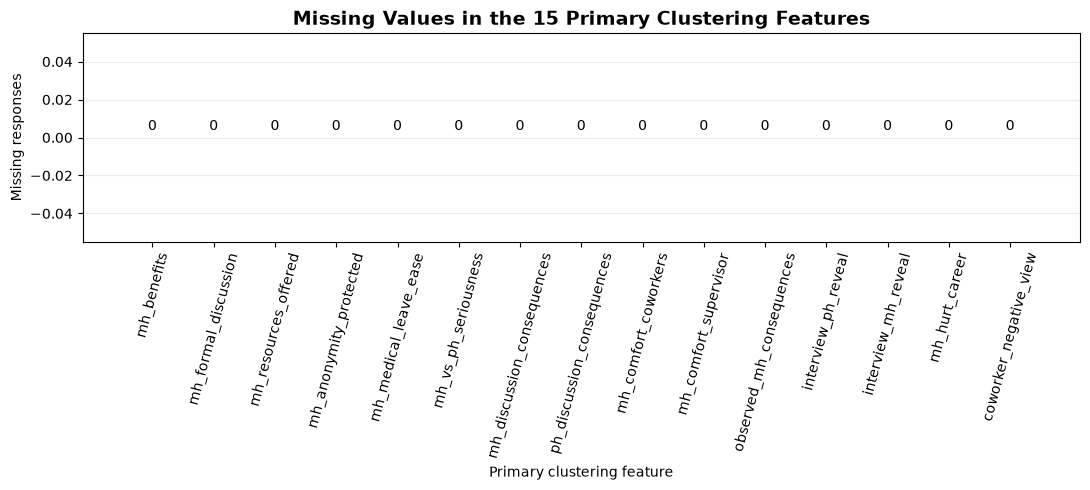

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    missing_audit["feature"],
    missing_audit["missing_count"],
)

ax.set_title(
    "Missing Values in the 15 Primary Clustering Features",
    fontsize=14,
    weight="bold",
)

ax.set_xlabel("Primary clustering feature")
ax.set_ylabel("Missing responses")

ax.tick_params(
    axis="x",
    labelrotation=75,
)

ax.bar_label(
    bars,
    padding=3,
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "primary_feature_missingness.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [19]:
if X_original.isna().any().any():
    missing_by_feature = (
        X_original.isna()
        .sum()
        .loc[lambda values: values > 0]
    )

    raise ValueError(
        "Unexpected missing values were found in the selected "
        "clustering features.\n\n"
        f"{missing_by_feature}\n\n"
        "Do not proceed with model-input creation until the "
        "source discrepancy has been investigated."
    )

print(
    "Missingness validation passed: "
    "all 15 selected features are complete."
)

Missingness validation passed: all 15 selected features are complete.


## 8. Audit Observed Response Categories

### 8.1 Why Category Auditing Matters

Categorical clustering depends on the categories present in the input data. Before encoding or calculating distances, it is important to confirm that:
- The observed responses are not accidentally split by whitespace.
- Unexpected categories are visible.
- Categories with different meanings remain separate.
- The ordinal leave-ease feature has the expected substantive levels.
- "I don't know" is retained as a valid response category rather than treated as a data-cleaning error.

For example, `Not eligible for coverage / N/A` under mental-health benefits should remain distinct from `No`. A respondent who is not eligible for a benefit is not necessarily reporting that the employer offers no benefits.

In [20]:
response_audit = []

for feature in PRIMARY_FEATURES:
    counts = (
        X_original[feature]
        .value_counts(dropna=False)
    )

    for category, count in counts.items():
        response_audit.append({
            "feature": feature,
            "response": category,
            "count": int(count),
            "percentage": (
                count / len(X_original) * 100
            ),
        })

response_audit = pd.DataFrame(response_audit)

response_audit["percentage"] = (
    response_audit["percentage"].round(2)
)

display(
    response_audit.sort_values(
        ["feature", "count"],
        ascending=[True, False],
    )
)

,feature,response,count,percentage
47,coworker_negative_view,Maybe,456,40.32
48,coworker_negative_view,"No, I don't think they would",302,26.70
49,coworker_negative_view,"Yes, I think they would",301,26.61
50,coworker_negative_view,"No, they do not",44,3.89
51,coworker_negative_view,"Yes, they do",28,2.48
39,interview_mh_reveal,No,710,62.78
40,interview_mh_reveal,Maybe,331,29.27
41,interview_mh_reveal,Yes,90,7.96
36,interview_ph_reveal,Maybe,475,42.00
37,interview_ph_reveal,No,368,32.54


### 8.2 Explicitly Validate the Leave-Ease Responses

In [21]:
LEAVE_FEATURE = "mh_medical_leave_ease"

EXPECTED_LEAVE_LEVELS = [
    "Very difficult",
    "Somewhat difficult",
    "Neither easy nor difficult",
    "Somewhat easy",
    "Very easy",
    "I don't know",
]

observed_leave_levels = set(
    X_original[LEAVE_FEATURE].dropna().unique()
)

expected_leave_levels = set(
    EXPECTED_LEAVE_LEVELS
)

if observed_leave_levels != expected_leave_levels:
    raise AssertionError(
        "Unexpected categories were found in mh_medical_leave_ease.\n"
        f"Expected: {sorted(expected_leave_levels)}\n"
        f"Observed: {sorted(observed_leave_levels)}"
    )

leave_counts = (
    X_original[LEAVE_FEATURE]
    .value_counts()
    .reindex(EXPECTED_LEAVE_LEVELS)
)

display(
    leave_counts.rename("respondents").to_frame()
)

,respondents
mh_medical_leave_ease,
Very difficult,116
Somewhat difficult,192
Neither easy nor difficult,176
Somewhat easy,279
Very easy,219
I don't know,149


The six observed responses are valid and must be retained.

For K-Modes and MCA, the six categories are handled as nominal response labels. For Gower, the five substantive categories receive an ordinal distance, while "I don't know" is treated as a separate nominal state.

### 8.3 Visualise Response Distributions

The following small-multiple chart displays the category distribution of each primary feature. Each subplot has its own category labels, making it possible to inspect imbalance and low-frequency responses without combining different questions into a misleading common scale.

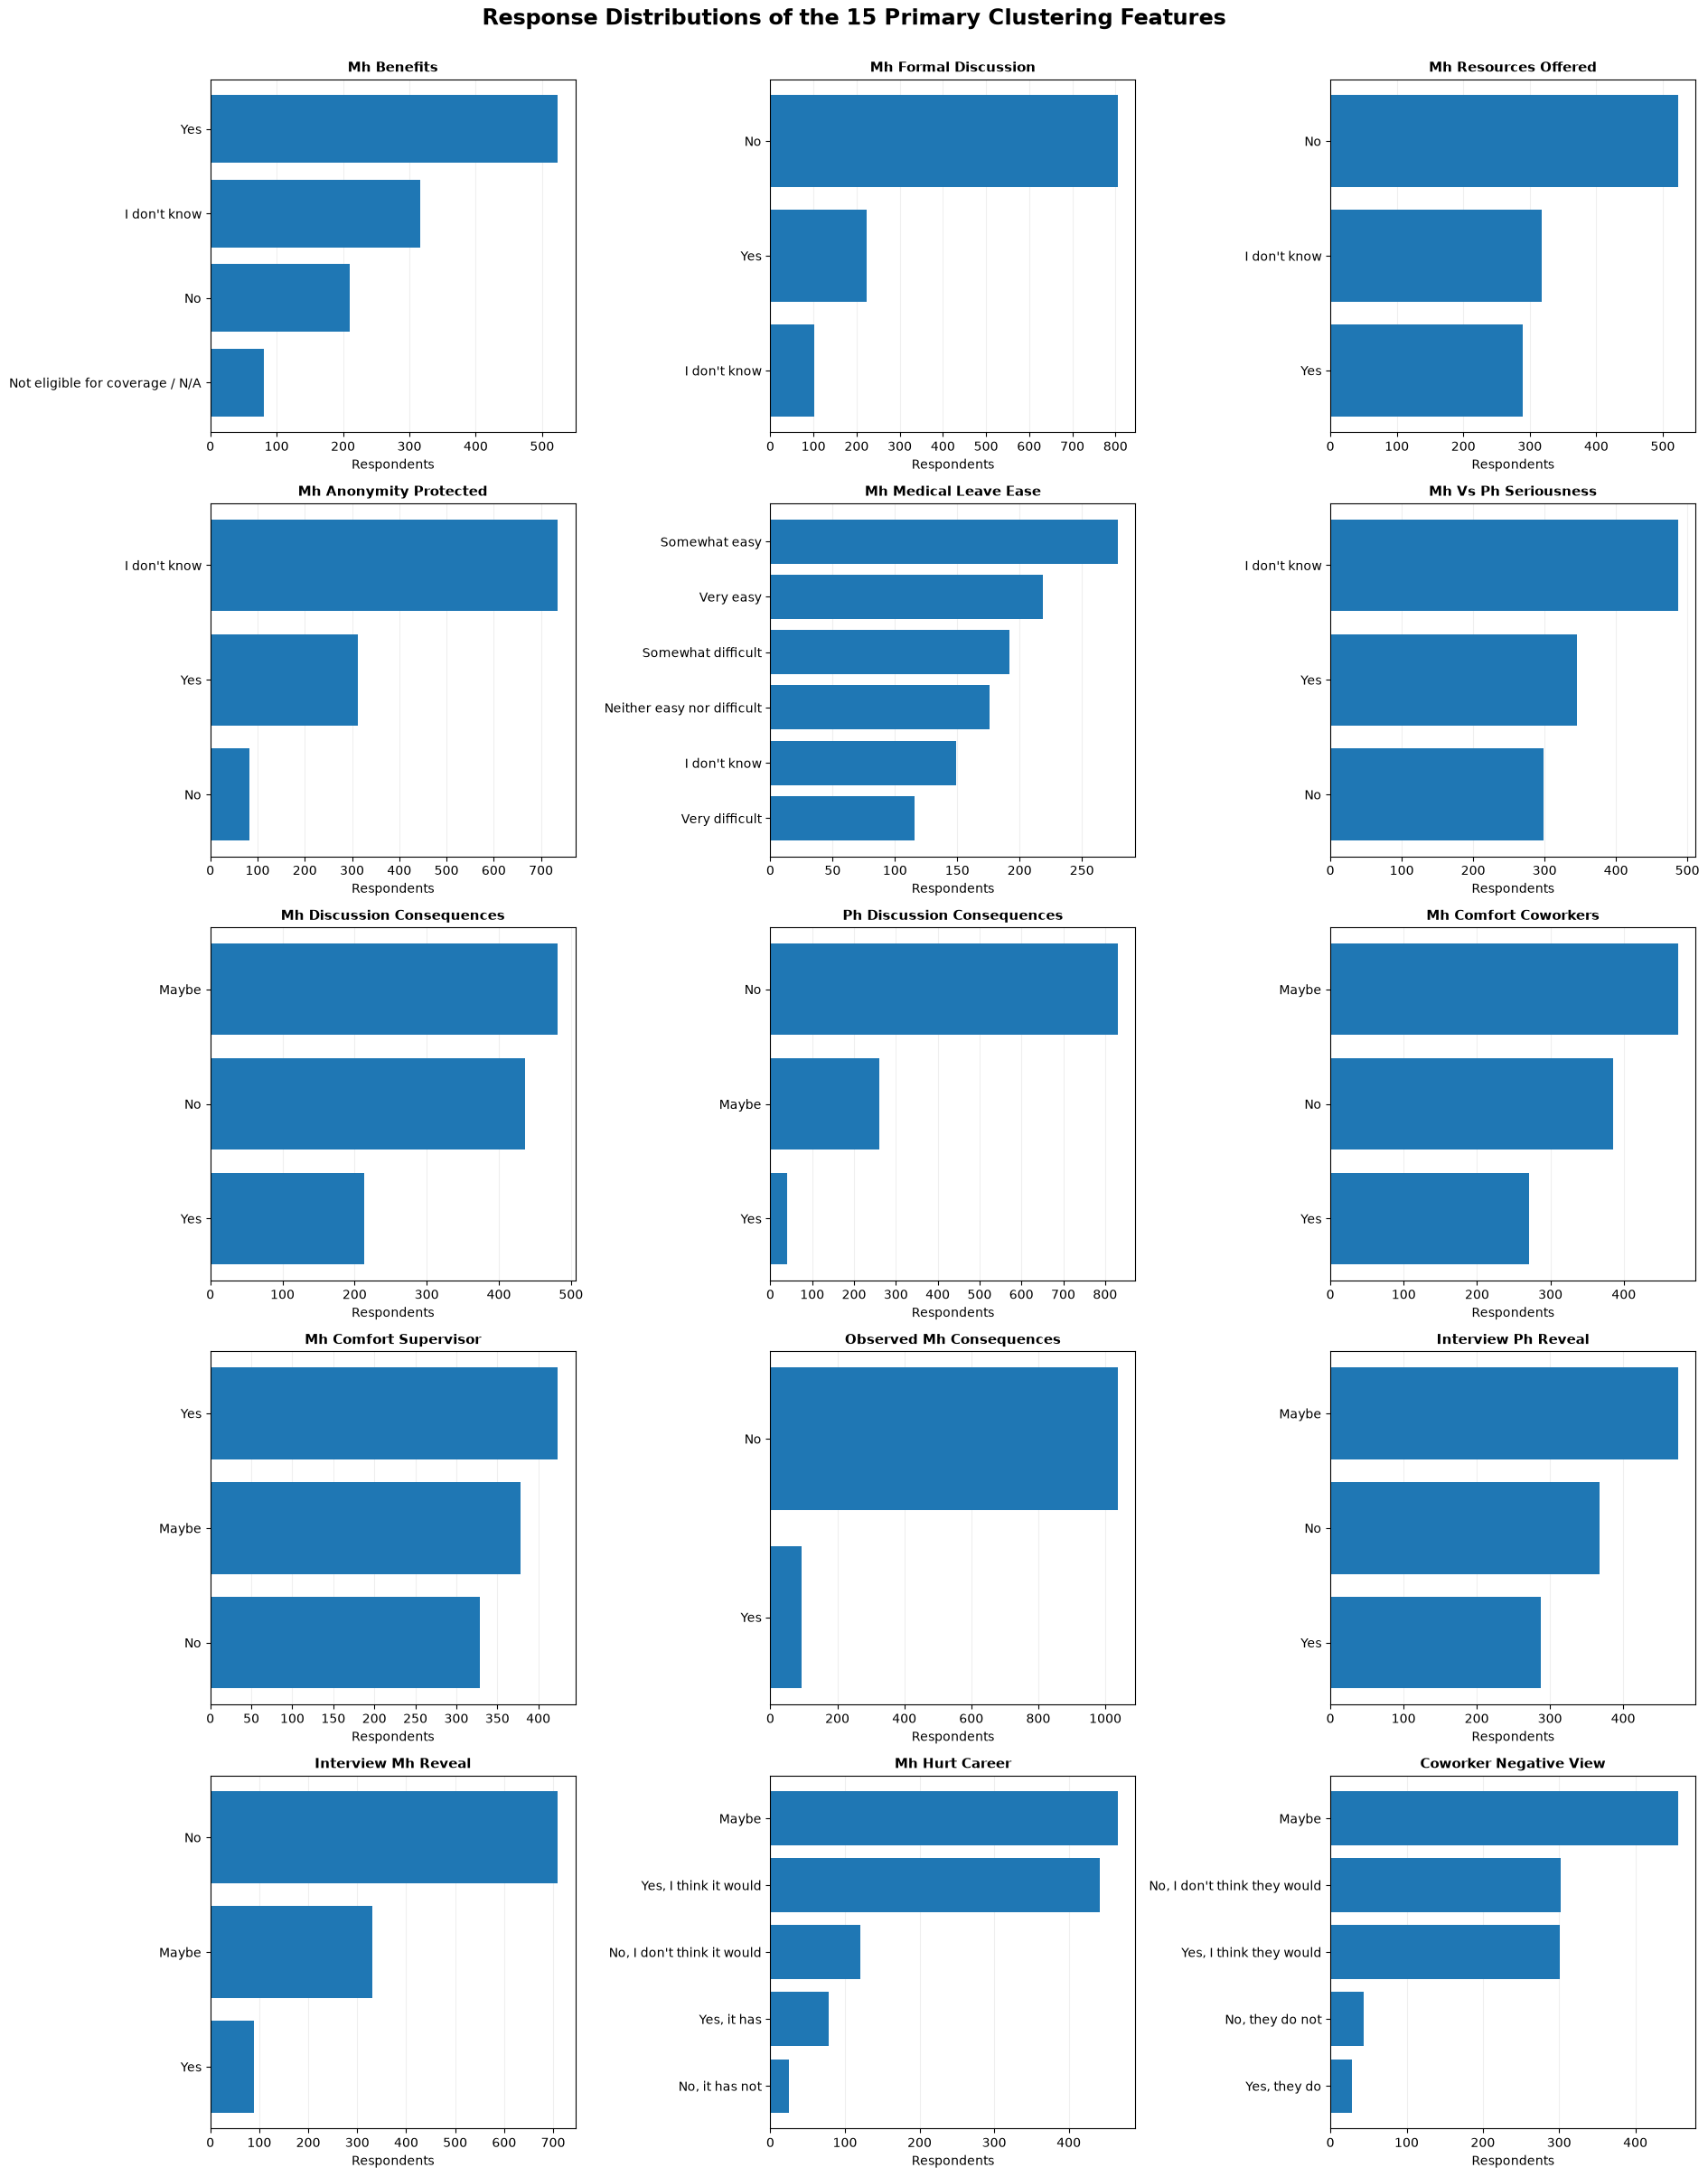

In [22]:
n_features = len(PRIMARY_FEATURES)

n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(19, 4.8 * n_rows),
)

axes = np.asarray(axes).reshape(-1)

for index, feature in enumerate(PRIMARY_FEATURES):
    ax = axes[index]

    counts = (
        X_original[feature]
        .value_counts()
        .sort_values(ascending=True)
    )

    ax.barh(
        counts.index.astype(str),
        counts.values,
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=11,
        weight="bold",
    )

    ax.set_xlabel("Respondents")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

for index in range(n_features, len(axes)):
    axes[index].set_visible(False)

fig.suptitle(
    "Response Distributions of the 15 Primary Clustering Features",
    fontsize=17,
    weight="bold",
    y=1.002,
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "primary_feature_distributions.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 8.4 Interpretation guidance

Use the distributions to identify:
- Dominant responses.
- Rare response categories.
- Questions with a high proportion of `I don't know` or `Maybe`.
- Questions with very uneven category distributions.
- Questions that may contribute limited differentiation because most respondents selected the same response.

Do not automatically remove a feature because one category is dominant. A dominant response may still be important to the workplace-climate construct. Feature removal should be based on substantive justification and evidence, not simply on a desire to make the categories more balanced.

## 9. Prepare the K-Modes Input

### 9.1 Categorical Representation for K-Modes

K-Modes is designed for categorical data. It compares categorical values using matching and mismatching categories rather than Euclidean distances between numerical measurements.

For this reason, the K-Modes input should contain the original categorical responses:
- No one-hot encoding.
- No arbitrary integer encoding.
- No standardisation or normalisation.
- No ordinal rank conversion.
- No imputation.

The leave-ease question is retained as six categorical labels for K-Modes. This is consistent with the algorithm's categorical matching approach; it does not preserve the ordinal spacing of the five substantive leave-ease responses.

In [23]:
X_kmodes = X_original.copy()

# Convert values to consistent strings for categorical algorithms.
# Missing values have already been checked and are not permitted.
X_kmodes = X_kmodes.astype("string")

assert X_kmodes.shape == (1131, 15)
assert not X_kmodes.isna().any().any()

assert all(
    pd.api.types.is_string_dtype(X_kmodes[column])
    for column in X_kmodes.columns
)

display(X_kmodes.head())

print("K-Modes input shape:", X_kmodes.shape)
print("K-Modes input contains only categorical response labels.")

,mh_benefits,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_vs_ph_seriousness,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,observed_mh_consequences,interview_ph_reveal,interview_mh_reveal,mh_hurt_career,coworker_negative_view
0,Not eligible for coverage / N/A,No,No,I don't know,Very easy,I don't know,No,No,Maybe,Yes,No,Maybe,Maybe,Maybe,"No, I don't think they would"
1,No,Yes,Yes,Yes,Somewhat easy,Yes,No,No,Maybe,Yes,No,Maybe,No,"No, I don't think it would","No, I don't think they would"
2,No,No,No,I don't know,Neither easy nor difficult,I don't know,Maybe,No,Maybe,Maybe,No,Yes,Yes,Maybe,Maybe
3,Yes,No,No,No,Neither easy nor difficult,No,Yes,Maybe,Maybe,No,No,Maybe,No,"Yes, I think it would",Maybe
4,Yes,No,Yes,Yes,Somewhat easy,No,Yes,Yes,Maybe,Yes,Yes,Yes,Maybe,"Yes, I think it would",Maybe


K-Modes input shape: (1131, 15)
K-Modes input contains only categorical response labels.


The K-Modes matrix is not one-hot encoded because K-Modes has its own categorical matching mechanism. One-hot encoding would change the representation and is not required for this algorithm.

The resulting matrix is saved separately so the modelling notebook can load it without repeating preparation.

## 10. Prepare the MCA indicator matrix

### 10.1 Why MCA is used before K-Means

K-Means calculates distances between numerical vectors. It is not appropriate to apply ordinary K-Means directly to text labels or arbitrary integer codes for nominal survey responses.

Multiple Correspondence Analysis (MCA) provides a categorical-data dimensionality-reduction approach. It works with an indicator representation of categorical variables and maps the categorical response patterns into a lower-dimensional numerical space.

The pipeline for this model is:
$$
\text{Categorical responses}
\rightarrow
\text{Indicator matrix}
\rightarrow
\text{MCA}
\rightarrow
\text{K-Means}
$$

The indicator matrix is prepared here. MCA itself will be fitted in the modelling notebook, where the number of retained dimensions can be selected and evaluated.

No `StandardScaler` is applied to the indicator matrix before MCA. MCA uses the categorical indicator structure and its associated chi-square geometry. Standardising the dummy columns as if they were continuous measurements would change that representation.

In [24]:
X_mca_indicator = pd.get_dummies(
    X_kmodes,
    columns=PRIMARY_FEATURES,
    prefix=PRIMARY_FEATURES,
    prefix_sep="=",
    dtype=np.uint8,
)

# Preserve the respondent row order.
X_mca_indicator = X_mca_indicator.reset_index(drop=True)

assert len(X_mca_indicator) == len(X_kmodes)
assert X_mca_indicator.shape[1] > X_mca_indicator.shape[0] * 0

assert set(np.unique(X_mca_indicator.to_numpy())).issubset(
    {0, 1}
)

# Each original feature contributes exactly one active category
# per respondent.
for feature in PRIMARY_FEATURES:
    indicator_columns = [
        column
        for column in X_mca_indicator.columns
        if column.startswith(f"{feature}=")
    ]

    row_sums = (
        X_mca_indicator[indicator_columns]
        .sum(axis=1)
    )

    assert row_sums.eq(1).all(), (
        f"Indicator validation failed for {feature}."
    )

print("MCA indicator matrix shape:", X_mca_indicator.shape)

display(X_mca_indicator.head())

MCA indicator matrix shape: (1131, 52)


,mh_benefits=I don't know,mh_benefits=No,mh_benefits=Not eligible for coverage / N/A,mh_benefits=Yes,mh_formal_discussion=I don't know,mh_formal_discussion=No,mh_formal_discussion=Yes,mh_resources_offered=I don't know,mh_resources_offered=No,mh_resources_offered=Yes,mh_anonymity_protected=I don't know,mh_anonymity_protected=No,mh_anonymity_protected=Yes,mh_medical_leave_ease=I don't know,mh_medical_leave_ease=Neither easy nor difficult,mh_medical_leave_ease=Somewhat difficult,mh_medical_leave_ease=Somewhat easy,mh_medical_leave_ease=Very difficult,mh_medical_leave_ease=Very easy,mh_vs_ph_seriousness=I don't know,mh_vs_ph_seriousness=No,mh_vs_ph_seriousness=Yes,mh_discussion_consequences=Maybe,mh_discussion_consequences=No,mh_discussion_consequences=Yes,ph_discussion_consequences=Maybe,ph_discussion_consequences=No,ph_discussion_consequences=Yes,mh_comfort_coworkers=Maybe,mh_comfort_coworkers=No,mh_comfort_coworkers=Yes,mh_comfort_supervisor=Maybe,mh_comfort_supervisor=No,mh_comfort_supervisor=Yes,observed_mh_consequences=No,observed_mh_consequences=Yes,interview_ph_reveal=Maybe,interview_ph_reveal=No,interview_ph_reveal=Yes,interview_mh_reveal=Maybe,interview_mh_reveal=No,interview_mh_reveal=Yes,mh_hurt_career=Maybe,"mh_hurt_career=No, I don't think it would","mh_hurt_career=No, it has not","mh_hurt_career=Yes, I think it would","mh_hurt_career=Yes, it has",coworker_negative_view=Maybe,"coworker_negative_view=No, I don't think they would","coworker_negative_view=No, they do not","coworker_negative_view=Yes, I think they would","coworker_negative_view=Yes, they do"
0,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0
1,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0
2,0,1,0,0,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0
3,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0
4,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,0,1,0,0,0,0


### 10.2 Interpretation of the Indicator Matrix

Each original categorical feature is represented by a group of binary columns, one for each observed response category.

For example, if a feature has three observed categories, it contributes three indicator columns. A respondent has a value of 1 in the column corresponding to their selected category and 0 in the other two columns.

The indicator matrix therefore contains more columns than the original 15-feature matrix. This is expected and is not an error.

The matrix is an intermediate representation for MCA. It is not the final K-Means input. The modelling notebook must fit MCA and use the resulting respondent coordinates for K-Means.

## 11. Prepare Typed Input for Gower Dissimilarity

### 11.1 Why Gower is Appropriate

The Gower dissimilarity coefficient is designed to compare observations containing different variable types. It can accommodate nominal and ordinal variables without treating arbitrary category codes as meaningful numerical distances.

For the selected features:
- Nominal responses use a simple match/mismatch distance.
- The five substantive leave-ease responses use a normalised ordinal distance.
- "I don't know" is handled as an unordered nominal response.

The typed input retains the original response labels. The measurement metadata is stored separately so that the distance calculation is explicit and reproducible.

### 11.2 Nominal Distance

For a nominal feature $(j)$, the pairwise dissimilarity between respondents $(i)$ and $(l)$ is:

$$
d_{ilj} =
\begin{cases}
0, & x_{ij}=x_{lj}\\
1, & x_{ij}\neq x_{lj}
\end{cases}
$$

This means that two different nominal categories are treated as different, but neither category is considered numerically higher or lower than the other.

### 11.3 Ordinal Distance for Leave-Ease Responses
The five substantive leave-ease categories are assigned ranks from 1 to 5. Their pairwise dissimilarity is:

$$
d_{ilj} =
\frac{|r_{ij}-r_{lj}|}{5-1}
$$

where $(r)$ is the substantive ordinal rank.

The denominator is 4 because the distance between the lowest and highest ranks must be normalised to the interval $([0,1])$.

Examples:
- Very difficult versus Very difficult: 0.
- Very difficult versus Somewhat difficult: 0.25.
- Very difficult versus Very easy: 1.
- Somewhat difficult versus Somewhat easy: 0.5.

`"I don't know"` is not assigned a rank. If either respondent selected `"I don't know"`, the comparison is nominal:
- `"I don't know"` versus `"I don't know"`: 0.
- `"I don't know"` versus any substantive category: 1.

This avoids falsely placing `"I don't know"` below Very difficult or treating it as a neutral response.

In [25]:
X_gower_typed = X_original.copy().astype("string")

assert X_gower_typed.shape == (1131, 15)
assert not X_gower_typed.isna().any().any()

display(X_gower_typed.head())

,mh_benefits,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_vs_ph_seriousness,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,observed_mh_consequences,interview_ph_reveal,interview_mh_reveal,mh_hurt_career,coworker_negative_view
0,Not eligible for coverage / N/A,No,No,I don't know,Very easy,I don't know,No,No,Maybe,Yes,No,Maybe,Maybe,Maybe,"No, I don't think they would"
1,No,Yes,Yes,Yes,Somewhat easy,Yes,No,No,Maybe,Yes,No,Maybe,No,"No, I don't think it would","No, I don't think they would"
2,No,No,No,I don't know,Neither easy nor difficult,I don't know,Maybe,No,Maybe,Maybe,No,Yes,Yes,Maybe,Maybe
3,Yes,No,No,No,Neither easy nor difficult,No,Yes,Maybe,Maybe,No,No,Maybe,No,"Yes, I think it would",Maybe
4,Yes,No,Yes,Yes,Somewhat easy,No,Yes,Yes,Maybe,Yes,Yes,Yes,Maybe,"Yes, I think it would",Maybe


## 12. Construct the Domain-Balanced Gower Dissimilarity Matrix

### 12.1 Why Domain Balancing is Applied

The selected feature set contains three domains with different numbers of features:
- Employer support and policy: 6 features.
- Psychological safety and observed stigma: 5 features.
- Disclosure and career climate: 4 features.

If all 15 feature distances were simply averaged, the six-feature employer-support domain would receive 6/15 of the total weight, while the four-feature disclosure domain would receive only 4/15.

That would make the representation depend partly on how many questions happened to be assigned to each domain.

Instead, this notebook calculates the average dissimilarity within each domain and then gives the three domain averages equal weight:

$$
D_{il} =
\frac{1}{3}
\left(
D_{il,\text{employer}}
+
D_{il,\text{psychological}}
+
D_{il,\text{disclosure}}
\right)
$$

Within each domain, its feature distances are averaged:

$$
D_{il,g} =
\frac{1}{p_g}
\sum_{j \in g} d_{ilj}
$$

where:
- $(g)$ represents a domain.
- $(p_g)$ is the number of features in that domain.
- $(d_{ilj})$ is the feature-level dissimilarity between respondents $(i)$ and $(l)$.

This gives each of the three workplace-climate domains one-third of the final dissimilarity.

It is a deliberate modelling choice, not an automatic property of Gower's original coefficient. It is used because Notebook 01 defines the 15 features as three distinct conceptual domains and the project intends those domains to contribute equally.

In [26]:
def nominal_dissimilarity(values):
    """
    Pairwise nominal dissimilarity.

    Same category = 0
    Different category = 1
    """
    values = np.asarray(values, dtype=object)

    return (
        values[:, None] != values[None, :]
    ).astype(np.float32)


def ordinal_with_unknown_dissimilarity(
    values,
    rank_mapping,
    unknown_label,
):
    """
    Pairwise dissimilarity for an ordinal feature that includes
    a separate unordered 'unknown' response.

    - Two substantive responses: normalised rank distance.
    - Two unknown responses: 0.
    - Unknown versus substantive response: 1.
    """
    values = np.asarray(values, dtype=object)

    n = len(values)

    distances = np.empty(
        (n, n),
        dtype=np.float32,
    )

    is_unknown = values == unknown_label

    # Map substantive categories to ordinal ranks.
    ranks = np.full(
        n,
        np.nan,
        dtype=np.float32,
    )

    for category, rank in rank_mapping.items():
        ranks[values == category] = rank

    # All non-unknown categories must have a declared rank.
    invalid_mask = (
        ~is_unknown
        & np.isnan(ranks)
    )

    if invalid_mask.any():
        invalid_values = np.unique(
            values[invalid_mask]
        ).tolist()

        raise ValueError(
            "Unexpected ordinal responses encountered: "
            f"{invalid_values}"
        )

    # Both substantive responses:
    # normalised absolute rank difference.
    both_substantive = (
        ~is_unknown[:, None]
        & ~is_unknown[None, :]
    )

    distances[both_substantive] = (
        np.abs(
            ranks[:, None] - ranks[None, :]
        )[both_substantive]
        / (len(rank_mapping) - 1)
    )

    # Both unknown responses have distance 0.
    both_unknown = (
        is_unknown[:, None]
        & is_unknown[None, :]
    )

    distances[both_unknown] = 0.0

    # Unknown versus substantive response has distance 1.
    one_unknown = (
        is_unknown[:, None]
        ^ is_unknown[None, :]
    )

    distances[one_unknown] = 1.0

    return distances

In [27]:
domain_dissimilarities = {}

feature_dissimilarities = {}

for domain, features in FEATURES_BY_DOMAIN.items():

    domain_feature_matrices = []

    for feature in features:

        values = X_gower_typed[feature].to_numpy(
            dtype=object
        )

        if feature in ORDINAL_FEATURES:
            distance_matrix = (
                ordinal_with_unknown_dissimilarity(
                    values=values,
                    rank_mapping=ORDINAL_FEATURES[feature],
                    unknown_label=(
                        UNKNOWN_ORDINAL_RESPONSES[feature]
                    ),
                )
            )

        else:
            distance_matrix = nominal_dissimilarity(
                values
            )

        feature_dissimilarities[feature] = (
            distance_matrix
        )

        domain_feature_matrices.append(
            distance_matrix
        )

    # Equal feature weighting within this domain.
    domain_matrix = np.mean(
        np.stack(domain_feature_matrices, axis=0),
        axis=0,
        dtype=np.float32,
    )

    domain_dissimilarities[domain] = (
        domain_matrix
    )

    print(
        f"{domain}: "
        f"{len(features)} features processed."
    )

employer_support: 6 features processed.
psychological_safety: 5 features processed.
disclosure_career_climate: 4 features processed.


In [28]:
domain_matrices = [
    domain_dissimilarities[domain]
    for domain in FEATURES_BY_DOMAIN
]

D_gower = np.mean(
    np.stack(domain_matrices, axis=0),
    axis=0,
    dtype=np.float32,
)

# Numerical housekeeping.
D_gower = (
    D_gower + D_gower.T
) / 2.0

np.fill_diagonal(D_gower, 0.0)

print("Gower dissimilarity matrix created.")
print("Shape:", D_gower.shape)
print("Data type:", D_gower.dtype)
print(
    "Estimated memory:",
    f"{D_gower.nbytes / (1024 ** 2):.2f} MiB",
)

Gower dissimilarity matrix created.
Shape: (1131, 1131)
Data type: float32
Estimated memory: 4.88 MiB


### 12.2 Validate the dissimilarity matrix

The matrix must satisfy the following conditions:
1. It must be square, with one row and one column per respondent.
2. Every value must be finite.
3. It must be symmetric.
4. Its diagonal must contain zeros.
5. Its values must lie between 0 and 1.

These checks confirm that the matrix is structurally suitable for downstream distance-based clustering.

In [29]:
n_respondents = len(X_gower_typed)

assert D_gower.shape == (
    n_respondents,
    n_respondents,
)

assert np.isfinite(D_gower).all()

assert np.allclose(
    D_gower,
    D_gower.T,
    atol=1e-7,
)

assert np.allclose(
    np.diag(D_gower),
    0.0,
    atol=1e-7,
)

assert D_gower.min() >= -1e-7
assert D_gower.max() <= 1.0 + 1e-7

print("Gower matrix validation passed.")
print(f"Minimum: {D_gower.min():.6f}")
print(f"Maximum: {D_gower.max():.6f}")
print(f"Mean:    {D_gower.mean():.6f}")

Gower matrix validation passed.
Minimum: 0.000000
Maximum: 1.000000
Mean:    0.566536


### 12.3 Visualise the Gower Dissimilarity Matrix

The complete dissimilarity matrix contains 1,131 rows and 1,131 columns. Plotting every respondent as a tick label would make the figure unreadable.

The visualisation below uses a reproducible random sample of 250 respondents. It is a visual diagnostic only; the full matrix remains unchanged and is used by the modelling notebook.

Higher values indicate greater dissimilarity between respondents. Lower values indicate more similar response profiles.

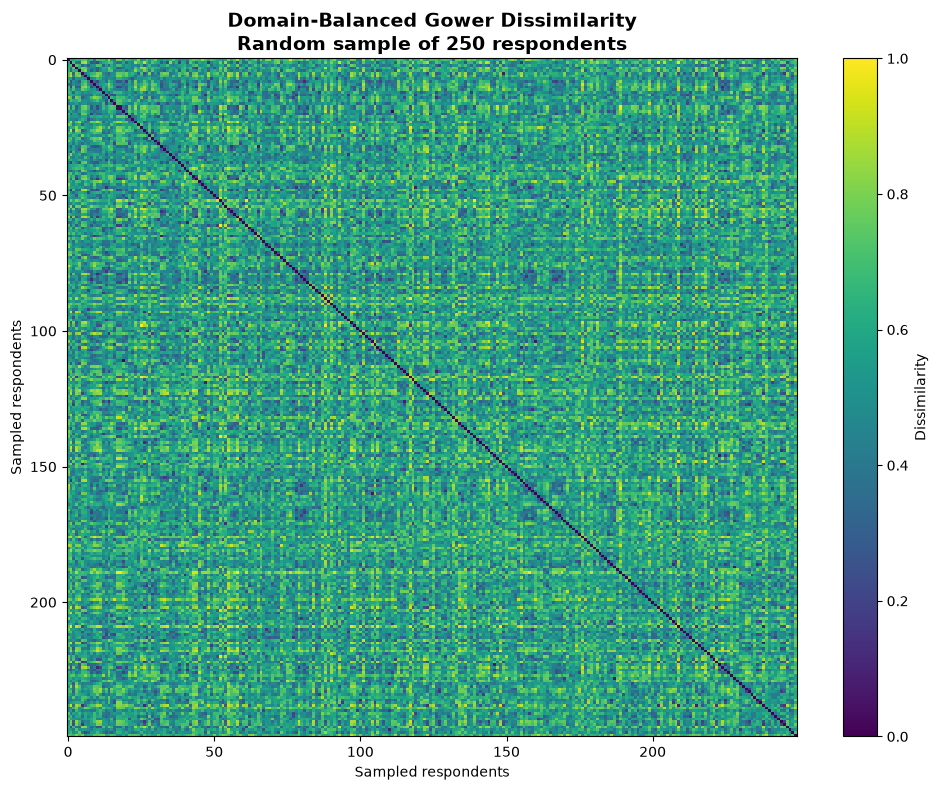

In [30]:
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(250, len(D_gower))

sample_indices = np.sort(
    rng.choice(
        len(D_gower),
        size=sample_size,
        replace=False,
    )
)

D_gower_sample = D_gower[
    np.ix_(sample_indices, sample_indices)
]

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    D_gower_sample,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=1,
)

ax.set_title(
    "Domain-Balanced Gower Dissimilarity\n"
    f"Random sample of {sample_size} respondents",
    fontsize=14,
    weight="bold",
)

ax.set_xlabel("Sampled respondents")
ax.set_ylabel("Sampled respondents")

colorbar = fig.colorbar(
    image,
    ax=ax,
)

colorbar.set_label("Dissimilarity")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gower_dissimilarity_sample.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 13. Feature Association Audit Using Cramér’s V

### 13.1 What Cramér’s V Measures
Cramér’s V is a statistical measure of association between two categorical variables. It is derived from the chi-square test of independence.

It measures the strength of association between two categorical variables. It does not indicate whether one variable causes another, and it does not identify a direction of effect.

In this project, Cramér’s V is used to investigate whether selected workplace-climate questions contain overlapping information. It is an exploratory feature-association audit, not an automatic feature-selection procedure.

A high association between two questions does not necessarily mean that one should be removed. Two questions can be related but still measure distinct aspects of workplace climate.

### 13.2 Cramér’s V Formula
The conventional Cramér’s V formula is:

$$
V =
\sqrt{
\frac{\chi^2}
{n \cdot \min(r-1,\;k-1)}
}
$$

Where:
- $(V)$ = Cramér’s V association coefficient.
- $(\chi^2)$ = chi-square statistic from the contingency table.
- $(n)$ = total number of observations used in the table.
- $(r)$ = number of rows in the contingency table.
- $(k)$ = number of columns in the contingency table.

The chi-square statistic measures the discrepancy between the observed cell frequencies and the frequencies expected if the two variables were independent.

The conventional coefficient is between 0 and 1:
- 0 indicates no observed association.
- Values closer to 1 indicate stronger association.

However, the conventional estimator can be positively biased, particularly when sample sizes are small relative to the number of categories. It can also be affected by table dimensions.

For this reason, this notebook uses the bias-corrected Cramér’s V estimator.

First, calculate:

$$
\phi^2 = \frac{\chi^2}{n}
$$

Then apply the bias correction:

$$
\phi^2_{\text{corr}} =
\max\left(
0,\;
\phi^2 -
\frac{(k-1)(r-1)}{n-1}
\right)
$$

Correct the table dimensions:

$$
r_{\text{corr}} =
r - \frac{(r-1)^2}{n-1}
$$

$$
k_{\text{corr}} =
k - \frac{(k-1)^2}{n-1}
$$

Finally:

$$
\boxed{
V_{\text{corr}} =
\sqrt{
\frac{
\phi^2_{\text{corr}}
}{
\min(r_{\text{corr}}-1,\;k_{\text{corr}}-1)
}
}
}
$$

The correction reduces the upward bias that can arise from finite samples and categorical tables with many levels.

### 13.3 How to Interpret Cramér’s V in This Project
Cramér’s V is useful for identifying pairs of questions that may be strongly associated. For example, a question about whether an employer provides mental-health benefits may be associated with a question about whether mental-health resources are offered.

However, the coefficient does not prove that the questions are duplicates. Their wording, conceptual meaning and role in the workplace-climate domains must also be considered.

The interpretation should therefore follow these principles:
1. Use the coefficient to identify potentially associated feature pairs.
2. Review the actual survey wording and the domains to which the features belong.
3. Distinguish conceptual overlap from true redundancy.
4. Do not automatically delete features based on a threshold.
5. Retain the 15 Notebook 01 features unless there is a clear, documented reason to change the scope.

For this audit, the ordinal leave-ease variable is treated as categorical. Cramér’s V does not use its rank spacing. Its ordinal structure is respected separately in the Gower distance calculation.

In [31]:
def cramers_v_bias_corrected(x, y):
    """
    Calculate bias-corrected Cramér's V for two categorical variables.

    Parameters
    ----------
    x, y : array-like
        Categorical observations with aligned row order.

    Returns
    -------
    float
        Bias-corrected Cramér's V in [0, 1], or np.nan if the
        contingency table is degenerate.
    """
    x = pd.Series(x)
    y = pd.Series(y)

    valid = x.notna() & y.notna()

    x = x.loc[valid]
    y = y.loc[valid]

    n = len(x)

    if n <= 1:
        return np.nan

    contingency = pd.crosstab(x, y)

    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        return np.nan

    chi2, _, _, _ = chi2_contingency(
        contingency.to_numpy(),
        correction=False,
    )

    r, k = contingency.shape

    phi2 = chi2 / n

    phi2_corrected = max(
        0.0,
        phi2 - (
            (k - 1) * (r - 1)
        ) / (n - 1),
    )

    r_corrected = (
        r - ((r - 1) ** 2) / (n - 1)
    )

    k_corrected = (
        k - ((k - 1) ** 2) / (n - 1)
    )

    denominator = min(
        r_corrected - 1,
        k_corrected - 1,
    )

    if denominator <= 0:
        return np.nan

    value = np.sqrt(
        phi2_corrected / denominator
    )

    return float(np.clip(value, 0.0, 1.0))

In [32]:
n_features = len(PRIMARY_FEATURES)

cramers_v_matrix = pd.DataFrame(
    np.eye(n_features),
    index=PRIMARY_FEATURES,
    columns=PRIMARY_FEATURES,
    dtype=float,
)

cramers_v_pairs = []

for i, feature_a in enumerate(PRIMARY_FEATURES):

    for j in range(i + 1, n_features):

        feature_b = PRIMARY_FEATURES[j]

        value = cramers_v_bias_corrected(
            X_original[feature_a],
            X_original[feature_b],
        )

        cramers_v_matrix.loc[
            feature_a,
            feature_b,
        ] = value

        cramers_v_matrix.loc[
            feature_b,
            feature_a,
        ] = value

        cramers_v_pairs.append({
            "feature_a": feature_a,
            "feature_b": feature_b,
            "domain_a": FEATURE_DOMAIN[feature_a],
            "domain_b": FEATURE_DOMAIN[feature_b],
            "cramers_v_bias_corrected": value,
        })

cramers_v_pairs = pd.DataFrame(
    cramers_v_pairs
).sort_values(
    "cramers_v_bias_corrected",
    ascending=False,
    na_position="last",
).reset_index(drop=True)

display(cramers_v_pairs)

,feature_a,feature_b,domain_a,domain_b,cramers_v_bias_corrected
0,mh_comfort_coworkers,mh_comfort_supervisor,psychological_safety,psychological_safety,0.476085
1,mh_hurt_career,coworker_negative_view,disclosure_career_climate,disclosure_career_climate,0.429113
2,interview_ph_reveal,interview_mh_reveal,disclosure_career_climate,disclosure_career_climate,0.424631
3,mh_discussion_consequences,mh_comfort_supervisor,psychological_safety,psychological_safety,0.423584
4,mh_medical_leave_ease,mh_discussion_consequences,employer_support,psychological_safety,0.421017
...,...,...,...,...,...
100,mh_resources_offered,interview_ph_reveal,employer_support,disclosure_career_climate,0.013176
101,mh_benefits,interview_ph_reveal,employer_support,disclosure_career_climate,0.000000
102,mh_formal_discussion,observed_mh_consequences,employer_support,psychological_safety,0.000000
103,mh_formal_discussion,interview_ph_reveal,employer_support,disclosure_career_climate,0.000000


### 13.4 Interpreting the association results

The pairwise table contains 105 unique feature pairs:

$$
\frac{15(15-1)}{2}=105
$$

The diagonal of the matrix is 1 because each feature is perfectly associated with itself. The off-diagonal values show the association between different features.

There is no universal Cramér’s V threshold that establishes redundancy for every dataset. A coefficient should be interpreted in context, taking into account the response distributions, question wording and conceptual domains.

A high coefficient can indicate that two questions tend to receive related answers. It does not establish that the questions are interchangeable.

The matrix is therefore used to inform the modelling discussion, not to remove features automatically.

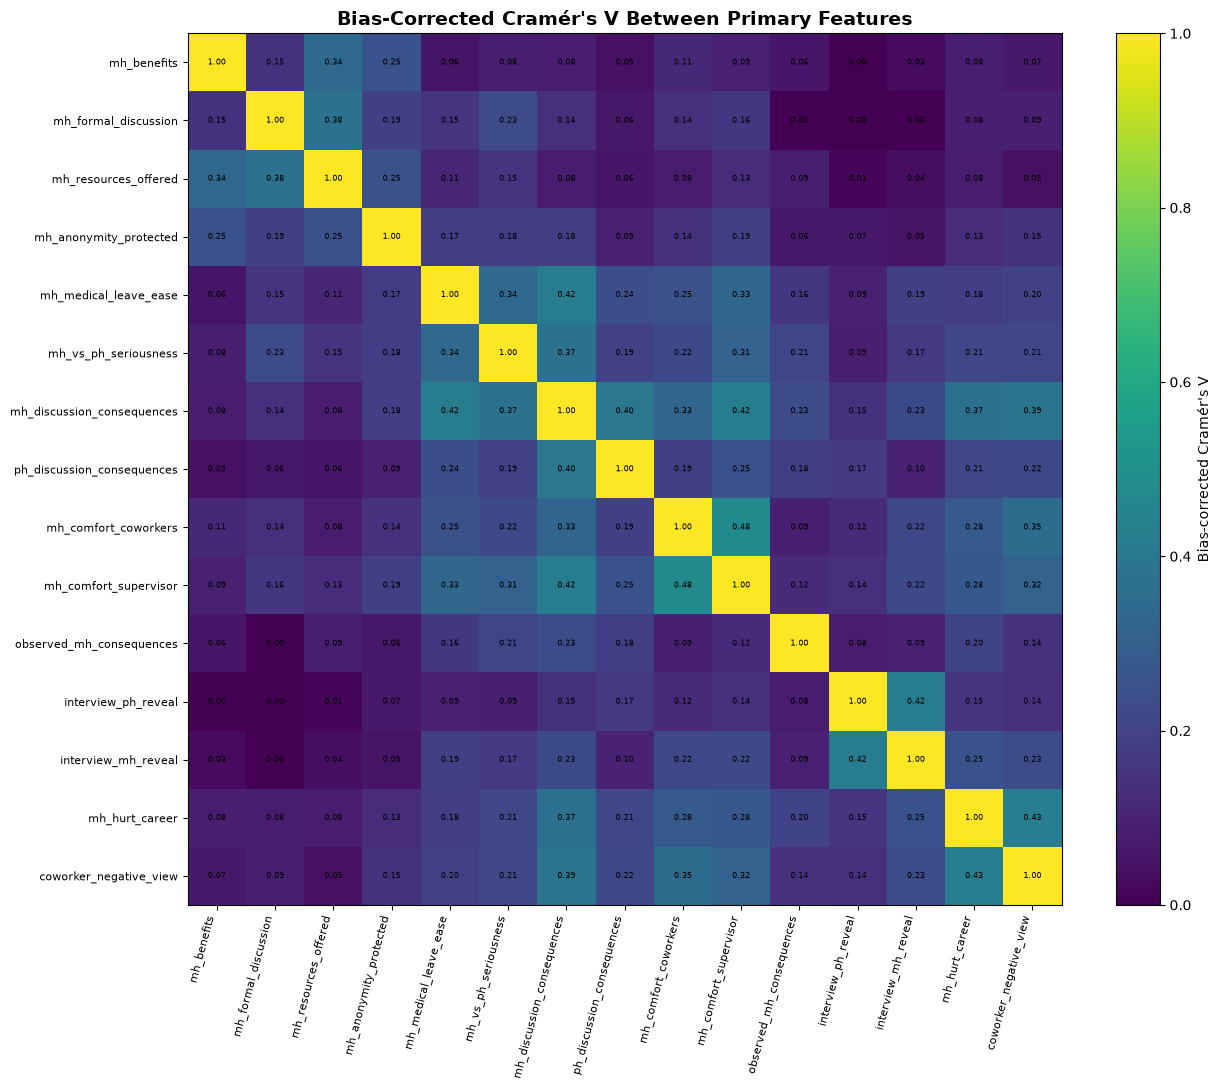

In [33]:
fig, ax = plt.subplots(figsize=(13, 11))

matrix_values = cramers_v_matrix.to_numpy(
    dtype=float
)

image = ax.imshow(
    matrix_values,
    vmin=0,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(PRIMARY_FEATURES))
)

ax.set_yticks(
    np.arange(len(PRIMARY_FEATURES))
)

ax.set_xticklabels(
    PRIMARY_FEATURES,
    rotation=75,
    ha="right",
    fontsize=8,
)

ax.set_yticklabels(
    PRIMARY_FEATURES,
    fontsize=8,
)

ax.set_title(
    "Bias-Corrected Cramér's V Between Primary Features",
    fontsize=14,
    weight="bold",
)

colorbar = fig.colorbar(
    image,
    ax=ax,
)

colorbar.set_label(
    "Bias-corrected Cramér's V"
)

# Annotate the matrix values.
for row in range(n_features):
    for column in range(n_features):
        value = matrix_values[row, column]

        if np.isfinite(value):
            ax.text(
                column,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=6,
            )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cramers_v_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [34]:
print("Ten strongest pairwise associations:")

display(
    cramers_v_pairs.head(10).style.format({
        "cramers_v_bias_corrected": "{:.3f}"
    })
)

Ten strongest pairwise associations:


,feature_a,feature_b,domain_a,domain_b,cramers_v_bias_corrected
0,mh_comfort_coworkers,mh_comfort_supervisor,psychological_safety,psychological_safety,0.476
1,mh_hurt_career,coworker_negative_view,disclosure_career_climate,disclosure_career_climate,0.429
2,interview_ph_reveal,interview_mh_reveal,disclosure_career_climate,disclosure_career_climate,0.425
3,mh_discussion_consequences,mh_comfort_supervisor,psychological_safety,psychological_safety,0.424
4,mh_medical_leave_ease,mh_discussion_consequences,employer_support,psychological_safety,0.421
5,mh_discussion_consequences,ph_discussion_consequences,psychological_safety,psychological_safety,0.398
6,mh_discussion_consequences,coworker_negative_view,psychological_safety,disclosure_career_climate,0.387
7,mh_formal_discussion,mh_resources_offered,employer_support,employer_support,0.375
8,mh_vs_ph_seriousness,mh_discussion_consequences,employer_support,psychological_safety,0.371
9,mh_discussion_consequences,mh_hurt_career,psychological_safety,disclosure_career_climate,0.366


### 13.5 Feature-Retention Decision

All 15 selected features are retained.

The association audit does not provide sufficient grounds to remove a feature by itself. Any future change to the feature set must be supported by the conceptual meaning of the questions, their response distributions and their effect on the clustering results.

This maintains consistency with Notebook 01 and prevents an exploratory association statistic from silently changing the original research scope.

## 14. Prepare the Respondent-to-Model Row Mapping

### 14.1 Why Row Lineage Matters

All algorithm-specific matrices must contain the same respondents in exactly the same order.

This is essential because the modelling notebook will compare cluster assignments across different representations. If one matrix has a different row order, a cluster label could be attached to the wrong respondent.

A separate mapping file records:
- The row index used by the modelling matrices.
- The corresponding row position in the renamed interim dataset.

The source row position is retained for traceability but is never included in a clustering feature matrix.

In [35]:
model_row_mapping = pd.DataFrame({
    "model_row_index": np.arange(
        len(cohort_clean),
        dtype=np.int64,
    ),
    "source_row_position": (
        cohort_clean["source_row_position"]
        .to_numpy(dtype=np.int64)
    ),
})

assert len(model_row_mapping) == len(X_kmodes)
assert len(model_row_mapping) == len(X_mca_indicator)
assert len(model_row_mapping) == len(X_gower_typed)

assert model_row_mapping[
    "model_row_index"
].is_unique

assert model_row_mapping[
    "source_row_position"
].is_unique

display(model_row_mapping.head())

,model_row_index,source_row_position
0,0,0
1,1,1
2,2,2
3,3,4
4,4,5


## 15. Final Quality Assurance

### 15.1 Validate All Modelling Representations
Before exporting the prepared data, the notebook performs a final set of structural and methodological checks.

The checks ensure that:
- The eligible cohort contains 1,131 respondents.
- Exactly 15 primary features are included.
- The K-Modes input contains the original categorical responses.
- The MCA input contains binary indicator columns.
- Each original feature contributes exactly one active indicator per respondent.
- The Gower input contains the same 15 features.
- The Gower matrix is finite, symmetric, bounded and has a zero diagonal.
- The respondent row mapping is consistent across all representations.
- No demographic or unrelated contextual variables have entered the clustering matrices.

In [36]:
# Cohort and feature scope

assert len(cohort_clean) == 1131
assert len(PRIMARY_FEATURES) == 15

assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert list(X_gower_typed.columns) == PRIMARY_FEATURES

# K-Modes validation

assert X_kmodes.shape == (1131, 15)
assert not X_kmodes.isna().any().any()

# MCA indicator validation

assert len(X_mca_indicator) == 1131
assert X_mca_indicator.shape[1] >= 15

assert not X_mca_indicator.isna().any().any()

assert set(
    np.unique(X_mca_indicator.to_numpy())
).issubset({0, 1})

for feature in PRIMARY_FEATURES:
    indicator_columns = [
        column
        for column in X_mca_indicator.columns
        if column.startswith(f"{feature}=")
    ]

    assert len(indicator_columns) >= 2

    assert (
        X_mca_indicator[indicator_columns]
        .sum(axis=1)
        .eq(1)
        .all()
    )

# Gower input and matrix validation

assert X_gower_typed.shape == (1131, 15)
assert not X_gower_typed.isna().any().any()

assert D_gower.shape == (1131, 1131)
assert np.isfinite(D_gower).all()

assert np.allclose(
    D_gower,
    D_gower.T,
    atol=1e-7,
)

assert np.allclose(
    np.diag(D_gower),
    0,
    atol=1e-7,
)

assert D_gower.min() >= -1e-7
assert D_gower.max() <= 1 + 1e-7

# Row alignment validation

assert len(model_row_mapping) == 1131

assert (
    model_row_mapping["model_row_index"]
    .to_numpy()
    == np.arange(1131)
).all()

assert (
    cohort_clean["source_row_position"]
    .to_numpy()
    == model_row_mapping["source_row_position"]
    .to_numpy()
).all()

# Feature exclusion validation

excluded_from_clustering = [
    "gender",
    "gender_profile",
    "age",
    "country",
    "state",
    "company_size",
    "work_remote",
]

for excluded_feature in excluded_from_clustering:
    assert excluded_feature not in X_kmodes.columns
    assert excluded_feature not in X_mca_indicator.columns
    assert excluded_feature not in X_gower_typed.columns

print("All final preparation quality checks passed.")

All final preparation quality checks passed.


## 16. Export the Prepared Datasets and Matrices

### 16.1 Export Strategy
The outputs are saved separately so that the modelling notebook can load the representation required by each algorithm.

|Output|Purpose|
|:--|:--|
|`osmi_2016_cleaned_respondents.csv`|Full cleaned respondent dataset, with harmonised gender profile|
|`osmi_2016_primary_cohort.csv`|Eligible 1,131-person cohort|
|`osmi_2016_model_row_mapping.csv`|Respondent row lineage|
|`osmi_2016_kmodes_input.csv`|Original categorical input for K-Modes|
|`osmi_2016_mca_indicator_matrix.csv`|One-hot indicator input for MCA|
|`osmi_2016_gower_typed_input.csv`|Typed 15-feature input for Gower|
|`osmi_2016_gower_dissimilarity.npy`|Full domain-balanced Gower matrix|
|`osmi_2016_feature_metadata.csv`|Feature domains and measurement metadata|
|`osmi_2016_cramers_v_matrix.csv`|Pairwise bias-corrected Cramér’s V matrix|
|`osmi_2016_cramers_v_pairs.csv`|Long-format pairwise association results|
|`osmi_2016_preparation_metadata.json`|Reproducibility and handoff information|

The full cleaned respondent file is retained for traceability and descriptive work. It is not a modelling matrix.

In [37]:
# Output paths

OUTPUT_FILES = {
    "cleaned_respondents": (
        PROCESSED_DIR
        / "osmi_2016_cleaned_respondents.csv"
    ),

    "primary_cohort": (
        PROCESSED_DIR
        / "osmi_2016_primary_cohort.csv"
    ),

    "row_mapping": (
        PROCESSED_DIR
        / "osmi_2016_model_row_mapping.csv"
    ),

    "kmodes_input": (
        PROCESSED_DIR
        / "osmi_2016_kmodes_input.csv"
    ),

    "mca_indicator_matrix": (
        PROCESSED_DIR
        / "osmi_2016_mca_indicator_matrix.csv"
    ),

    "gower_typed_input": (
        PROCESSED_DIR
        / "osmi_2016_gower_typed_input.csv"
    ),

    "gower_dissimilarity": (
        PROCESSED_DIR
        / "osmi_2016_gower_dissimilarity.npy"
    ),

    "feature_metadata": (
        PROCESSED_DIR
        / "osmi_2016_feature_metadata.csv"
    ),

    "cramers_v_matrix": (
        PROCESSED_DIR
        / "osmi_2016_cramers_v_matrix.csv"
    ),

    "cramers_v_pairs": (
        PROCESSED_DIR
        / "osmi_2016_cramers_v_pairs.csv"
    ),

    "preparation_metadata": (
        PROCESSED_DIR
        / "osmi_2016_preparation_metadata.json"
    ),
}

# Save respondent datasets

df_clean.to_csv(
    OUTPUT_FILES["cleaned_respondents"],
    index=False,
)

cohort_clean.to_csv(
    OUTPUT_FILES["primary_cohort"],
    index=False,
)

# Save row mapping

model_row_mapping.to_csv(
    OUTPUT_FILES["row_mapping"],
    index=False,
)

# Save algorithm-specific inputs

X_kmodes.to_csv(
    OUTPUT_FILES["kmodes_input"],
    index=False,
)

X_mca_indicator.to_csv(
    OUTPUT_FILES["mca_indicator_matrix"],
    index=False,
)

X_gower_typed.to_csv(
    OUTPUT_FILES["gower_typed_input"],
    index=False,
)

np.save(
    OUTPUT_FILES["gower_dissimilarity"],
    D_gower,
    allow_pickle=False,
)

# Save feature and association metadata

feature_metadata.to_csv(
    OUTPUT_FILES["feature_metadata"],
    index=False,
)

cramers_v_matrix.to_csv(
    OUTPUT_FILES["cramers_v_matrix"],
)

cramers_v_pairs.to_csv(
    OUTPUT_FILES["cramers_v_pairs"],
    index=False,
)

print("All primary preparation outputs have been saved.")

All primary preparation outputs have been saved.


### 16.2 Save Preparation Metadata

The metadata file records the cohort size, selected features, feature domains, measurement treatments, missing-value policy and algorithm-specific representations.

This provides a machine-readable record of the preparation decisions and makes the modelling handoff easier to audit.

In [38]:
preparation_metadata = {
    "project": "OSMI 2016 Mental Health in Technology-related Jobs",

    "notebook": "02_data_preparation",

    "random_state": RANDOM_STATE,

    "source_file": str(INPUT_FILE),

    "source_respondents": int(len(df_clean)),

    "eligible_cohort_size": int(len(cohort_clean)),

    "cohort_definition": (
        "self_employed == 0 AND "
        "(tech_company == 1 OR tech_role == 1)"
    ),

    "primary_feature_count": int(len(PRIMARY_FEATURES)),

    "primary_features": PRIMARY_FEATURES,

    "feature_domains": {
        domain: features
        for domain, features in FEATURES_BY_DOMAIN.items()
    },

    "feature_domain_weights": {
        domain: 1 / len(FEATURES_BY_DOMAIN)
        for domain in FEATURES_BY_DOMAIN
    },

    "feature_measurement_types": {
        feature: (
            "ordinal_with_nominal_unknown"
            if feature in ORDINAL_FEATURES
            else "nominal"
        )
        for feature in PRIMARY_FEATURES
    },

    "ordinal_feature": {
        "name": LEAVE_FEATURE,
        "ranks": ORDINAL_FEATURES[LEAVE_FEATURE],
        "unknown_response": (
            UNKNOWN_ORDINAL_RESPONSES[LEAVE_FEATURE]
        ),
        "unknown_treatment": (
            "Nominal: 0 for unknown-unknown; "
            "1 for unknown-substantive comparison."
        ),
    },

    "missing_value_policy": (
        "No imputation. The selected 15 features are expected "
        "to have zero missing values in the eligible cohort. "
        "Unexpected missing values cause validation to fail."
    ),

    "gender_policy": (
        "Gender is harmonised for descriptive profiling only. "
        "It is excluded from all clustering representations. "
        "Missing gender values remain missing."
    ),

    "gower_method": {
        "nominal_distance": "0 for match; 1 for mismatch",
        "ordinal_distance": (
            "Absolute rank difference divided by the "
            "maximum substantive rank difference."
        ),
        "domain_balancing": (
            "Average feature dissimilarity within each domain, "
            "then equal average of the three domain-level "
            "dissimilarities."
        ),
        "matrix_shape": list(D_gower.shape),
        "matrix_dtype": str(D_gower.dtype),
        "matrix_minimum": float(D_gower.min()),
        "matrix_maximum": float(D_gower.max()),
        "matrix_mean": float(D_gower.mean()),
    },

    "association_audit": {
        "method": "Bias-corrected Cramer's V",
        "number_of_features": int(len(PRIMARY_FEATURES)),
        "number_of_unique_pairs": int(
            len(cramers_v_pairs)
        ),
        "purpose": (
            "Exploratory categorical association audit. "
            "No feature is automatically removed."
        ),
    },

    "algorithm_inputs": {
        "K-Modes": (
            "osmi_2016_kmodes_input.csv"
        ),
        "MCA plus K-Means": (
            "osmi_2016_mca_indicator_matrix.csv; "
            "fit MCA in the modelling notebook."
        ),
        "Agglomerative hierarchical clustering": (
            "osmi_2016_gower_dissimilarity.npy"
        ),
        "HDBSCAN": (
            "osmi_2016_gower_dissimilarity.npy"
        ),
    },

    "model_fitting_performed": False,

    "mca_fitting_performed": False,

    "output_directory": str(PROCESSED_DIR),
}

with open(
    OUTPUT_FILES["preparation_metadata"],
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        preparation_metadata,
        file,
        indent=4,
        ensure_ascii=False,
    )

print("Preparation metadata saved.")

Preparation metadata saved.


## 17. Verify the Exported Files

### 17.1 Output Verification
The final check confirms that each expected output exists and has a non-zero file size.

It also reloads the Gower matrix from disk and confirms that its dimensions match the modelling cohort.

In [39]:
export_audit = []

for name, path in OUTPUT_FILES.items():

    exists = path.exists()

    size_bytes = (
        path.stat().st_size
        if exists
        else 0
    )

    export_audit.append({
        "output": name,
        "filename": path.name,
        "exists": exists,
        "size_kb": round(
            size_bytes / 1024,
            2,
        ),
    })

export_audit = pd.DataFrame(export_audit)

display(export_audit)

assert export_audit["exists"].all()

assert (
    export_audit["size_kb"] > 0
).all()

# Reload and validate the saved Gower matrix.
D_saved = np.load(
    OUTPUT_FILES["gower_dissimilarity"],
    allow_pickle=False,
)

assert D_saved.shape == (1131, 1131)

assert np.allclose(
    D_saved,
    D_gower,
    atol=1e-7,
)

print("All exported files verified.")

,output,filename,exists,size_kb
0,cleaned_respondents,osmi_2016_cleaned_respondents.csv,True,1044.50
1,primary_cohort,osmi_2016_primary_cohort.csv,True,814.10
2,row_mapping,osmi_2016_model_row_mapping.csv,True,10.25
3,kmodes_input,osmi_2016_kmodes_input.csv,True,129.04
4,mca_indicator_matrix,osmi_2016_mca_indicator_matrix.csv,True,117.53
5,gower_typed_input,osmi_2016_gower_typed_input.csv,True,129.04
6,gower_dissimilarity,osmi_2016_gower_dissimilarity.npy,True,4996.85
7,feature_metadata,osmi_2016_feature_metadata.csv,True,1.46
8,cramers_v_matrix,osmi_2016_cramers_v_matrix.csv,True,4.62
9,cramers_v_pairs,osmi_2016_cramers_v_pairs.csv,True,10.75


All exported files verified.


## 18. Final Findings and Modelling Handoff
### 18.1 Prepared Dataset
The preparation pipeline is designed around the eligible cohort of 1,131 technology-sector respondents. The primary clustering analysis retains the 15 workplace-climate features defined in Notebook 01.

The features represent three conceptual domains:
1. Employer support and policy.
2. Psychological safety and observed stigma.
3. Disclosure and career climate.

The feature scope has not been expanded to include demographics, age, personal mental-health history, location or general employment characteristics.

### 18.2 Missing Values
No imputation has been performed on the selected clustering features because the supplied eligible cohort has no missing values in those variables.

The three missing gender values in the full source dataset remain missing. Gender is used for descriptive profiling only and is excluded from the clustering matrices.

### 18.3 Categorical and Ordinal Treatment
The 14 nominal features retain their categorical response labels.

The leave-ease feature retains its five substantive ordinal levels for Gower distance calculations. "I don't know" remains an unordered nominal response.

The different algorithmic representations are intentional:
- K-Modes uses categorical response labels.
- MCA uses a binary indicator matrix.
- Gower uses explicitly typed feature dissimilarities.

### 18.4 Categorical Association
Bias-corrected Cramér’s V has been calculated for all 105 unique pairs of primary features.

The association analysis is used to understand relationships between the survey questions. It does not establish causality and does not automatically remove features.

### 18.5 Gower Distance
The Gower dissimilarity matrix uses nominal matching for nominal features and normalised rank distance for the five substantive leave-ease responses.

The three conceptual domains receive equal overall weight. This prevents the number of questions assigned to a domain from determining its total influence on respondent dissimilarity.

The full matrix is saved as a NumPy array for use by the two Gower-based clustering methods.

### 18.6 Algorithm-Specific Handoff

|Algorithm|	Input|	Modelling notebook responsibility|
|:--|:--|:--|
|K-Modes|	`osmi_2016_kmodes_input.csv`|	Fit candidate K-Modes solutions; assess cost and stability|
|MCA + K-Means|	`osmi_2016_mca_indicator_matrix.csv`|	Fit MCA, select dimensions, fit K-Means and evaluate solutions|
|Agglomerative hierarchical clustering|	`osmi_2016_gower_dissimilarity.npy`|	Fit average-linkage clustering using precomputed Gower dissimilarity|
|HDBSCAN|	`osmi_2016_gower_dissimilarity.npy`|	Fit HDBSCAN using the precomputed distance matrix, subject to the installed package's supported input format|

### 18.7 Evaluation Responsibilities

The modelling and evaluation notebook must evaluate the four methods using metrics appropriate to their representations.

|Model|	Relevant evaluation|
|:--|:--|
|K-Modes|	Clustering cost, repeated-run stability and resampling stability|
|MCA + K-Means|	Silhouette score, Davies–Bouldin index, Calinski–Harabasz index and stability|
|Agglomerative + Gower|	Gower-based silhouette and cophenetic correlation|
|HDBSCAN + Gower|	DBCV, noise proportion, cluster persistence and membership strengths|

These metrics do not all measure the same thing. In particular, metric values from different representations should not be compared as if they were directly interchangeable.

The final clustering decision must consider cluster quality, stability, interpretability, noise and the practical meaning of the resulting workplace-climate profiles.

### 18.8 Final output
The preparation notebook has produced the following core modelling artefacts:
- A categorical matrix for K-Modes.
- An indicator matrix for MCA.
- A typed feature matrix for Gower.
- A full domain-balanced Gower dissimilarity matrix.
- Feature metadata and row lineage.
- A Cramér’s V association audit.
- Figures documenting the cohort, feature distributions, missingness, gender profile and association structure.

No clustering models have been fitted in this notebook. The next notebook should load these saved artefacts and begin model development.